In [3]:
!pip install -q kagglehub

import kagglehub
import os

path = kagglehub.dataset_download("gti-upm/leapgestrecog")

print("Dataset Path:", path)
print("Download Successful!")


100%|██████████| 2.13G/2.13G [00:56<00:00, 40.6MB/s]

Extracting files...


Dataset Path: /root/.cache/kagglehub/datasets/gti-upm/leapgestrecog/versions/1
Download Successful!


In [10]:
import os

print("Dataset Path:", path)

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

Dataset Path: /kaggle/input/leapgestrecog
leapgestrecog/
  leapGestRecog/
    07/
    05/
    06/
    02/
    04/
    00/
    08/
    09/
    03/
    01/
  leapgestrecog/
    leapGestRecog/


In [11]:
image_extensions = (".png", ".jpg", ".jpeg")

total_images = 0

for root, dirs, files in os.walk(path):
    total_images += sum(
        file.lower().endswith(image_extensions)
        for file in files
    )

print("Total Images:", total_images)

Total Images: 40000


In [12]:
gesture_names = [
    "palm",
    "l",
    "fist",
    "fist_moved",
    "thumb",
    "index",
    "ok",
    "palm_moved",
    "c",
    "down"
]

print("Total Classes:", len(gesture_names))

for i, gesture in enumerate(gesture_names):
    print(i, ":", gesture)

Total Classes: 10
0 : palm
1 : l
2 : fist
3 : fist_moved
4 : thumb
5 : index
6 : ok
7 : palm_moved
8 : c
9 : down


Images found: 40000


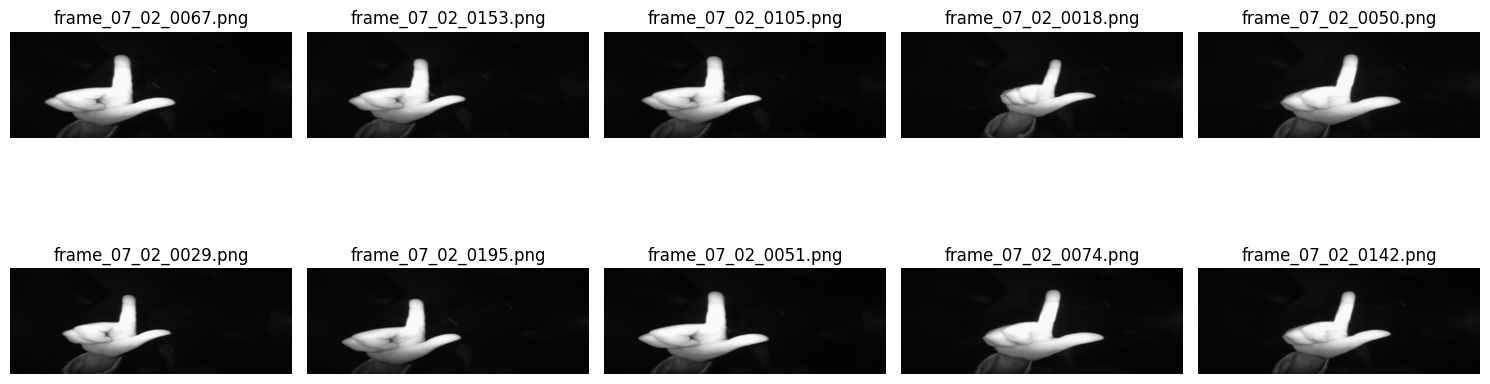

In [13]:
import matplotlib.pyplot as plt
from PIL import Image
import glob

image_paths = glob.glob(
    os.path.join(path, "**", "*.png"),
    recursive=True
)

print("Images found:", len(image_paths))

plt.figure(figsize=(15, 6))

for i in range(10):
    img = Image.open(image_paths[i])

    plt.subplot(2, 5, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(os.path.basename(image_paths[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [32]:
import numpy as np
import os
import re

from tensorflow.keras.preprocessing.image import load_img, img_to_array

IMG_SIZE = 64

X = []
y = []

for image_path in image_paths:

    folder_name = os.path.basename(
        os.path.dirname(image_path)
    )

    match = re.match(r"^(\d+)", folder_name)

    if match is None:
        continue

    label = int(match.group(1))

    img = load_img(
        image_path,
        color_mode="grayscale",
        target_size=(IMG_SIZE, IMG_SIZE)
    )

    img_array = img_to_array(img)

    X.append(img_array)
    y.append(label)

X = np.array(X, dtype="float32") / 255.0
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique labels:", np.unique(y))

X shape: (40000, 64, 64, 1)
y shape: (40000,)
Unique labels: [ 1  2  3  4  5  6  7  8  9 10]


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (32000, 64, 64, 1)
Testing data: (8000, 64, 64, 1)
Training labels: (32000,)
Testing labels: (8000,)


In [18]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

model = Sequential([
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(64, 64, 1)),

    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.5),

    Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,914 (2.61 MB)

 Trainable params: 683,914 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [21]:
import numpy as np

print("Old labels:", np.unique(y))

y = y - 1

print("New labels:", np.unique(y))

Old labels: [ 1  2  3  4  5  6  7  8  9 10]
New labels: [0 1 2 3 4 5 6 7 8 9]


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (32000, 64, 64, 1)
Testing: (8000, 64, 64, 1)


In [23]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 189s 236ms/step - accuracy: 0.9188 - loss: 0.2432 - val_accuracy: 0.9995 - val_loss: 0.0022
Epoch 2/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 198s 231ms/step - accuracy: 0.9920 - loss: 0.0248 - val_accuracy: 1.0000 - val_loss: 6.6084e-04
Epoch 3/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 207s 238ms/step - accuracy: 0.9946 - loss: 0.0177 - val_accuracy: 1.0000 - val_loss: 1.9751e-04
Epoch 4/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 195s 229ms/step - accuracy: 0.9956 - loss: 0.0135 - val_accuracy: 1.0000 - val_loss: 7.9792e-05
Epoch 5/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 182s 228ms/step - accuracy: 0.9977 - loss: 0.0080 - val_accuracy: 1.0000 - val_loss: 1.5940e-05
Epoch 6/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 191s 239ms/step - accuracy: 0.9976 - loss: 0.0102 - val_accuracy: 1.0000 - val_loss: 5.0051e-05
Epoch 7/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 187s 234ms/step - accuracy: 0.9980 - loss: 0.0054 - val_accuracy: 0.9994 - val_loss: 0.0023
Epoch 8/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 192s 240ms/step 

In [24]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 65ms/step - accuracy: 1.0000 - loss: 9.6506e-05
Test Loss: 9.650599531596527e-05
Test Accuracy: 100.0 %


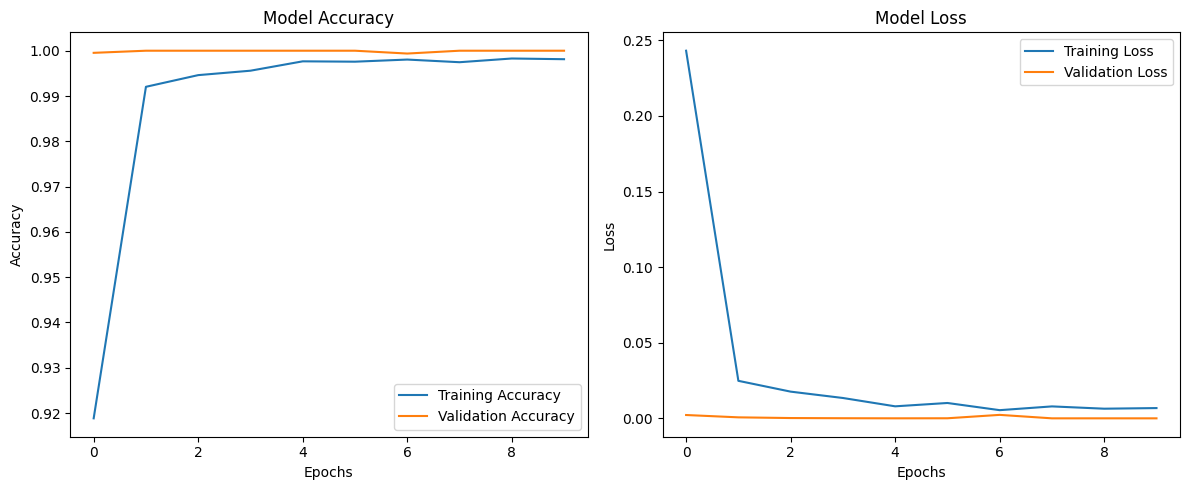

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [26]:
from sklearn.metrics import classification_report

y_pred = np.argmax(model.predict(X_test), axis=1)

print(classification_report(y_test, y_pred))

250/250 ━━━━━━━━━━━━━━━━━━━━ 18s 71ms/step
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       800
           1       1.00      1.00      1.00       800
           2       1.00      1.00      1.00       800
           3       1.00      1.00      1.00       800
           4       1.00      1.00      1.00       800
           5       1.00      1.00      1.00       800
           6       1.00      1.00      1.00       800
           7       1.00      1.00      1.00       800
           8       1.00      1.00      1.00       800
           9       1.00      1.00      1.00       800

    accuracy                           1.00      8000
   macro avg       1.00      1.00      1.00      8000
weighted avg       1.00      1.00      1.00      8000



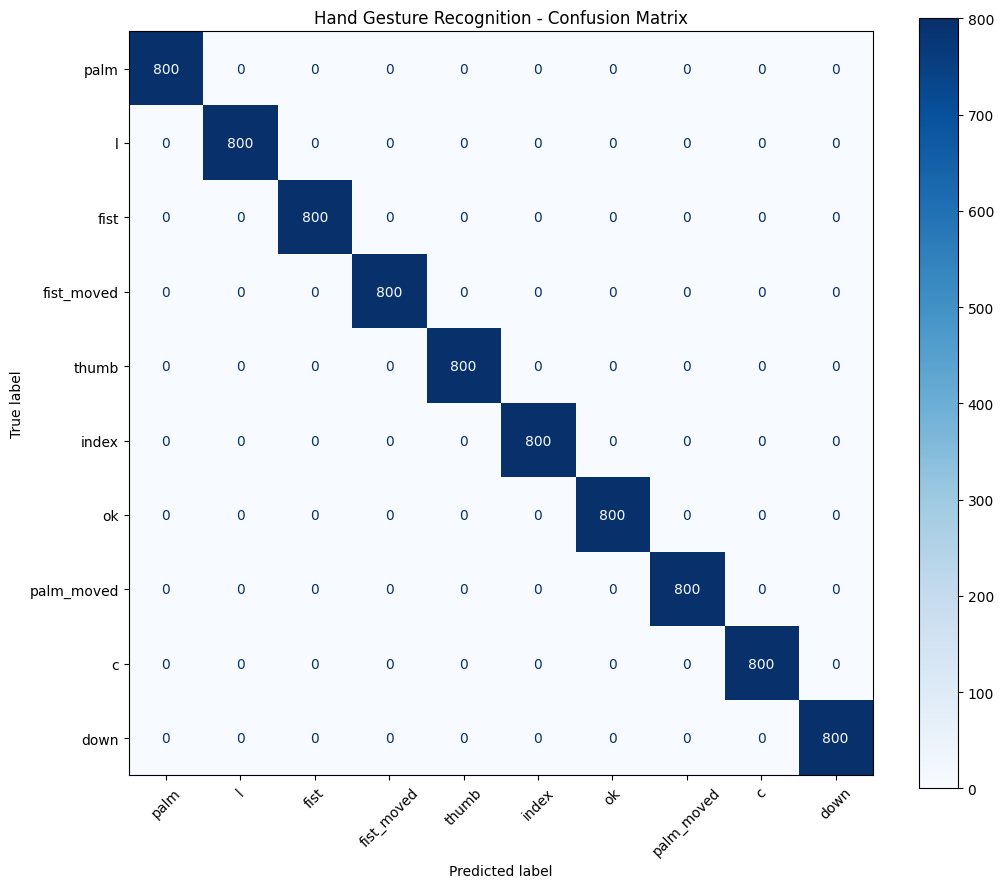

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=gesture_names
)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(cmap="Blues", xticks_rotation=45, ax=ax)
plt.title("Hand Gesture Recognition - Confusion Matrix")
plt.show()

In [28]:
model.save("hand_gesture_model.keras")

print("Model saved successfully!")

Model saved successfully!


Predicted Gesture: ok
Actual Gesture: ok


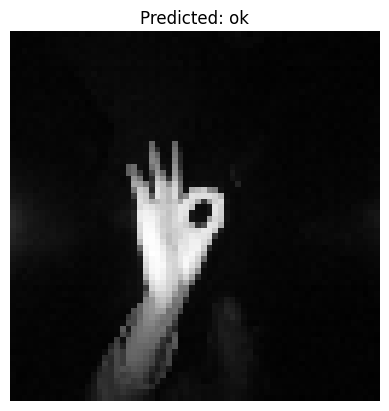

In [29]:
import random
import matplotlib.pyplot as plt

idx = random.randint(0, len(X_test) - 1)

sample = X_test[idx]

prediction = model.predict(
    np.expand_dims(sample, axis=0),
    verbose=0
)

predicted_class = np.argmax(prediction)
actual_class = y_test[idx]

print("Predicted Gesture:", gesture_names[predicted_class])
print("Actual Gesture:", gesture_names[actual_class])

plt.imshow(sample.squeeze(), cmap="gray")
plt.title("Predicted: " + gesture_names[predicted_class])
plt.axis("off")
plt.show()

In [30]:
model.save("hand_gesture_model.keras")

In [31]:
from google.colab import files

files.download("hand_gesture_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>